# EDA 01 — Statistik Deskriptif Harga Saham
Notebook ini digunakan untuk analisis deskriptif data historis harga saham sektor energi LQ45 periode Januari 2022–Juni 2026.

Analisis meliputi:
1. Import library dan konfigurasi path
2. Load data harga saham
3. Pemeriksaan missing value
4. Statistik deskriptif harga saham
5. Uji stasioneritas ADF
6. Visualisasi distribusi harga saham
7. Penyimpanan output tabel dan gambar

Output digunakan pada subbab:
**4.1.3.1 Statistik Deskriptif Harga Saham**

# Import library & path

In [1]:
# ============================================================
# CELL 1 — IMPORT LIBRARY & KONFIGURASI PATH
# ============================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import skew, kurtosis
from statsmodels.tsa.stattools import adfuller

# Font thesis
mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['figure.dpi'] = 200
plt.rcParams['figure.dpi'] = 200

# Root project (naik 2 folder dari EDA)
ROOT_DIR = Path('../../')

RAW_DIR = ROOT_DIR / '03_dataset' / 'raw'
PROCESSED_DIR = ROOT_DIR / '03_dataset' / 'processed'
OUTPUT_DIR = ROOT_DIR / '06_dokumen_tesis'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FILE = RAW_DIR / 'harga_saham_raw.csv'

print("Current Dir :", Path.cwd())
print("Input File  :", INPUT_FILE.resolve())
print("File Exists :", INPUT_FILE.exists())

Current Dir : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\EDA
Input File  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\harga_saham_raw.csv
File Exists : True


# Load Data Harga Saham
Data harga saham harian menggunakan adjusted closing price agar perhitungan return lebih representatif terhadap aksi korporasi seperti stock split dan dividen.

In [2]:
# ============================================================
# CELL 2 — LOAD DATA HARGA SAHAM
# ============================================================

INPUT_FILE = RAW_DIR / "harga_saham_raw.csv"

# Cek apakah file ada
if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {INPUT_FILE.resolve()}"
    )

# Load dataset
df = pd.read_csv(INPUT_FILE, encoding='utf-8-sig')

# Rapikan nama kolom
df.columns = df.columns.str.strip()

print("Kolom dataset:")
print(df.columns.tolist())

# --- Standardisasi nama kolom (biar aman) ---
# sesuaikan kalau hasil yfinance pakai lowercase / underscore
rename_map = {
    'adj close': 'Adj Close',
    'adj_close': 'Adj Close',
    'date': 'Date',
    'kode_emiten': 'Kode_Emiten'
}

df.rename(
    columns={c: rename_map.get(c.lower(), c) for c in df.columns},
    inplace=True
)

# Validasi kolom wajib
required_cols = ['Date', 'Kode_Emiten', 'Adj Close']
missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    # Kolom di dataset sebenarnya bernama 'Emiten' (bukan 'Kode_Emiten')
    rename_map = {
        'adj close': 'Adj Close',
        'adj_close': 'Adj Close',
        'date': 'Date',
        'kode_emiten': 'Kode_Emiten',
        'emiten': 'Kode_Emiten'
    }

    df.rename(
        columns={c: rename_map.get(c.lower(), c) for c in df.columns},
        inplace=True
    )

    # Validasi kolom wajib
    required_cols = ['Date', 'Kode_Emiten', 'Adj Close']
    missing_cols = [col for col in required_cols if col not in df.columns]

    if missing_cols:
        raise ValueError(f"Kolom berikut tidak ditemukan: {missing_cols}")

# Convert tipe data
df['Date'] = pd.to_datetime(df['Date'])

# Urutkan time series (WAJIB untuk data saham)
df = df.sort_values(
    ['Kode_Emiten', 'Date']
).reset_index(drop=True)

# Gunakan adjusted close
price_col = 'Adj Close'

print("Shape data:", df.shape)
display(df.head())

Kolom dataset:
['Date', 'Open', 'High', 'Low', 'Close', 'Adj_Close', 'Volume', 'Emiten']
Shape data: (7979, 8)


,Date,Open,High,Low,Close,Adj Close,Volume,Kode_Emiten
0,2022-01-03,135.0,135.0,135.0,135.0,125.224686,34289600,ADMR
1,2022-01-04,182.0,182.0,182.0,182.0,168.821442,22170900,ADMR
2,2022-01-05,220.0,244.0,220.0,244.0,226.332031,43203600,ADMR
3,2022-01-06,304.0,304.0,304.0,304.0,281.987457,52097500,ADMR
4,2022-01-07,380.0,380.0,380.0,380.0,352.484314,19248600,ADMR


# Pemeriksaan Missing Value dan Struktur Data
Tahapan ini memastikan kualitas data sebelum dilakukan analisis statistik.

In [3]:
# ============================================================
# CELL 3 — DATA INFO & MISSING VALUE
# ============================================================

print("INFO DATA")
print("="*60)
print(df.info())

print("\nMissing Value:")
missing = df.isnull().sum()
display(missing[missing > 0])

missing.to_csv(
    OUTPUT_DIR / "missing_value_harga_saham.csv",
    encoding='utf-8-sig'
)

INFO DATA
<class 'pandas.DataFrame'>
RangeIndex: 7979 entries, 0 to 7978
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         7979 non-null   datetime64[us]
 1   Open         7979 non-null   float64       
 2   High         7979 non-null   float64       
 3   Low          7979 non-null   float64       
 4   Close        7979 non-null   float64       
 5   Adj Close    7979 non-null   float64       
 6   Volume       7979 non-null   int64         
 7   Kode_Emiten  7979 non-null   str           
dtypes: datetime64[us](1), float64(5), int64(1), str(1)
memory usage: 530.0 KB
None

Missing Value:


Series([], dtype: int64)

## Statistik Deskriptif Harga Saham
Statistik yang dihitung:
- Mean
- Standard Deviation
- Minimum
- Maximum
- Skewness
- Kurtosis

Output digunakan sebagai **Tabel 4.5**.

In [4]:
# ============================================================
# CELL 4 — STATISTIK DESKRIPTIF
# ============================================================

summary = []

for kode in sorted(df['Kode_Emiten'].unique()):
    sub = df[df['Kode_Emiten'] == kode][price_col].dropna()

    summary.append({
        'Kode_Emiten': kode,
        'Mean': sub.mean(),
        'Std': sub.std(),
        'Min': sub.min(),
        'Max': sub.max(),
        'Skewness': skew(sub),
        'Kurtosis': kurtosis(sub)
    })

desc_table = pd.DataFrame(summary)
desc_table = desc_table.round(4)

display(desc_table)

desc_table.to_csv(
    OUTPUT_DIR / "Tabel_4_5_statistik_deskriptif_harga.csv",
    index=False,
    encoding='utf-8-sig'
)

,Kode_Emiten,Mean,Std,Min,Max,Skewness,Kurtosis
0,ADMR,1314.9407,372.2437,125.2247,2773.4949,0.6552,0.8102
1,ADRO,1395.6952,459.8868,506.4847,2600.0000,0.4559,-0.2801
2,AKRA,1095.8040,241.7082,505.7661,1553.3195,-0.7436,-0.1248
3,ITMG,19757.9975,3858.2165,8924.8350,28902.7246,-1.3187,1.4294
4,MEDC,1009.4120,330.6027,378.4356,1942.4753,-0.2437,-0.4229
5,PGAS,1236.9923,299.6747,808.6768,2271.0823,0.7590,0.0985
6,PTBA,2060.7390,383.4808,1102.6633,3038.3130,-0.6074,0.2967


## Uji Stasioneritas ADF
Uji Augmented Dickey-Fuller digunakan untuk mengetahui apakah data harga saham bersifat stasioner.

Kriteria:
- p-value < 0.05 → stasioner
- p-value ≥ 0.05 → tidak stasioner

In [5]:
# ============================================================
# CELL 5 — UJI ADF
# ============================================================

adf_results = []

for kode in sorted(df['Kode_Emiten'].unique()):
    series = df[df['Kode_Emiten'] == kode][price_col].dropna()

    result = adfuller(series)

    adf_results.append({
        'Kode_Emiten': kode,
        'ADF Statistic': result[0],
        'p-value': result[1],
        'Status': 'Stasioner' if result[1] < 0.05 else 'Tidak Stasioner'
    })

adf_table = pd.DataFrame(adf_results).round(6)

display(adf_table)

adf_table.to_csv(
    OUTPUT_DIR / "Tabel_ADF_Harga_Saham.csv",
    index=False,
    encoding='utf-8-sig'
)

,Kode_Emiten,ADF Statistic,p-value,Status
0,ADMR,-3.415843,0.010430,Stasioner
1,ADRO,-0.713287,0.843278,Tidak Stasioner
2,AKRA,-2.060867,0.260539,Tidak Stasioner
3,ITMG,-2.310535,0.168593,Tidak Stasioner
4,MEDC,-1.992888,0.289700,Tidak Stasioner
5,PGAS,-1.475123,0.545780,Tidak Stasioner
6,PTBA,-2.214776,0.200926,Tidak Stasioner


## Histogram Distribusi Harga Saham
Visualisasi distribusi adjusted closing price masing-masing emiten.
Output digunakan sebagai **Gambar 4.4**.

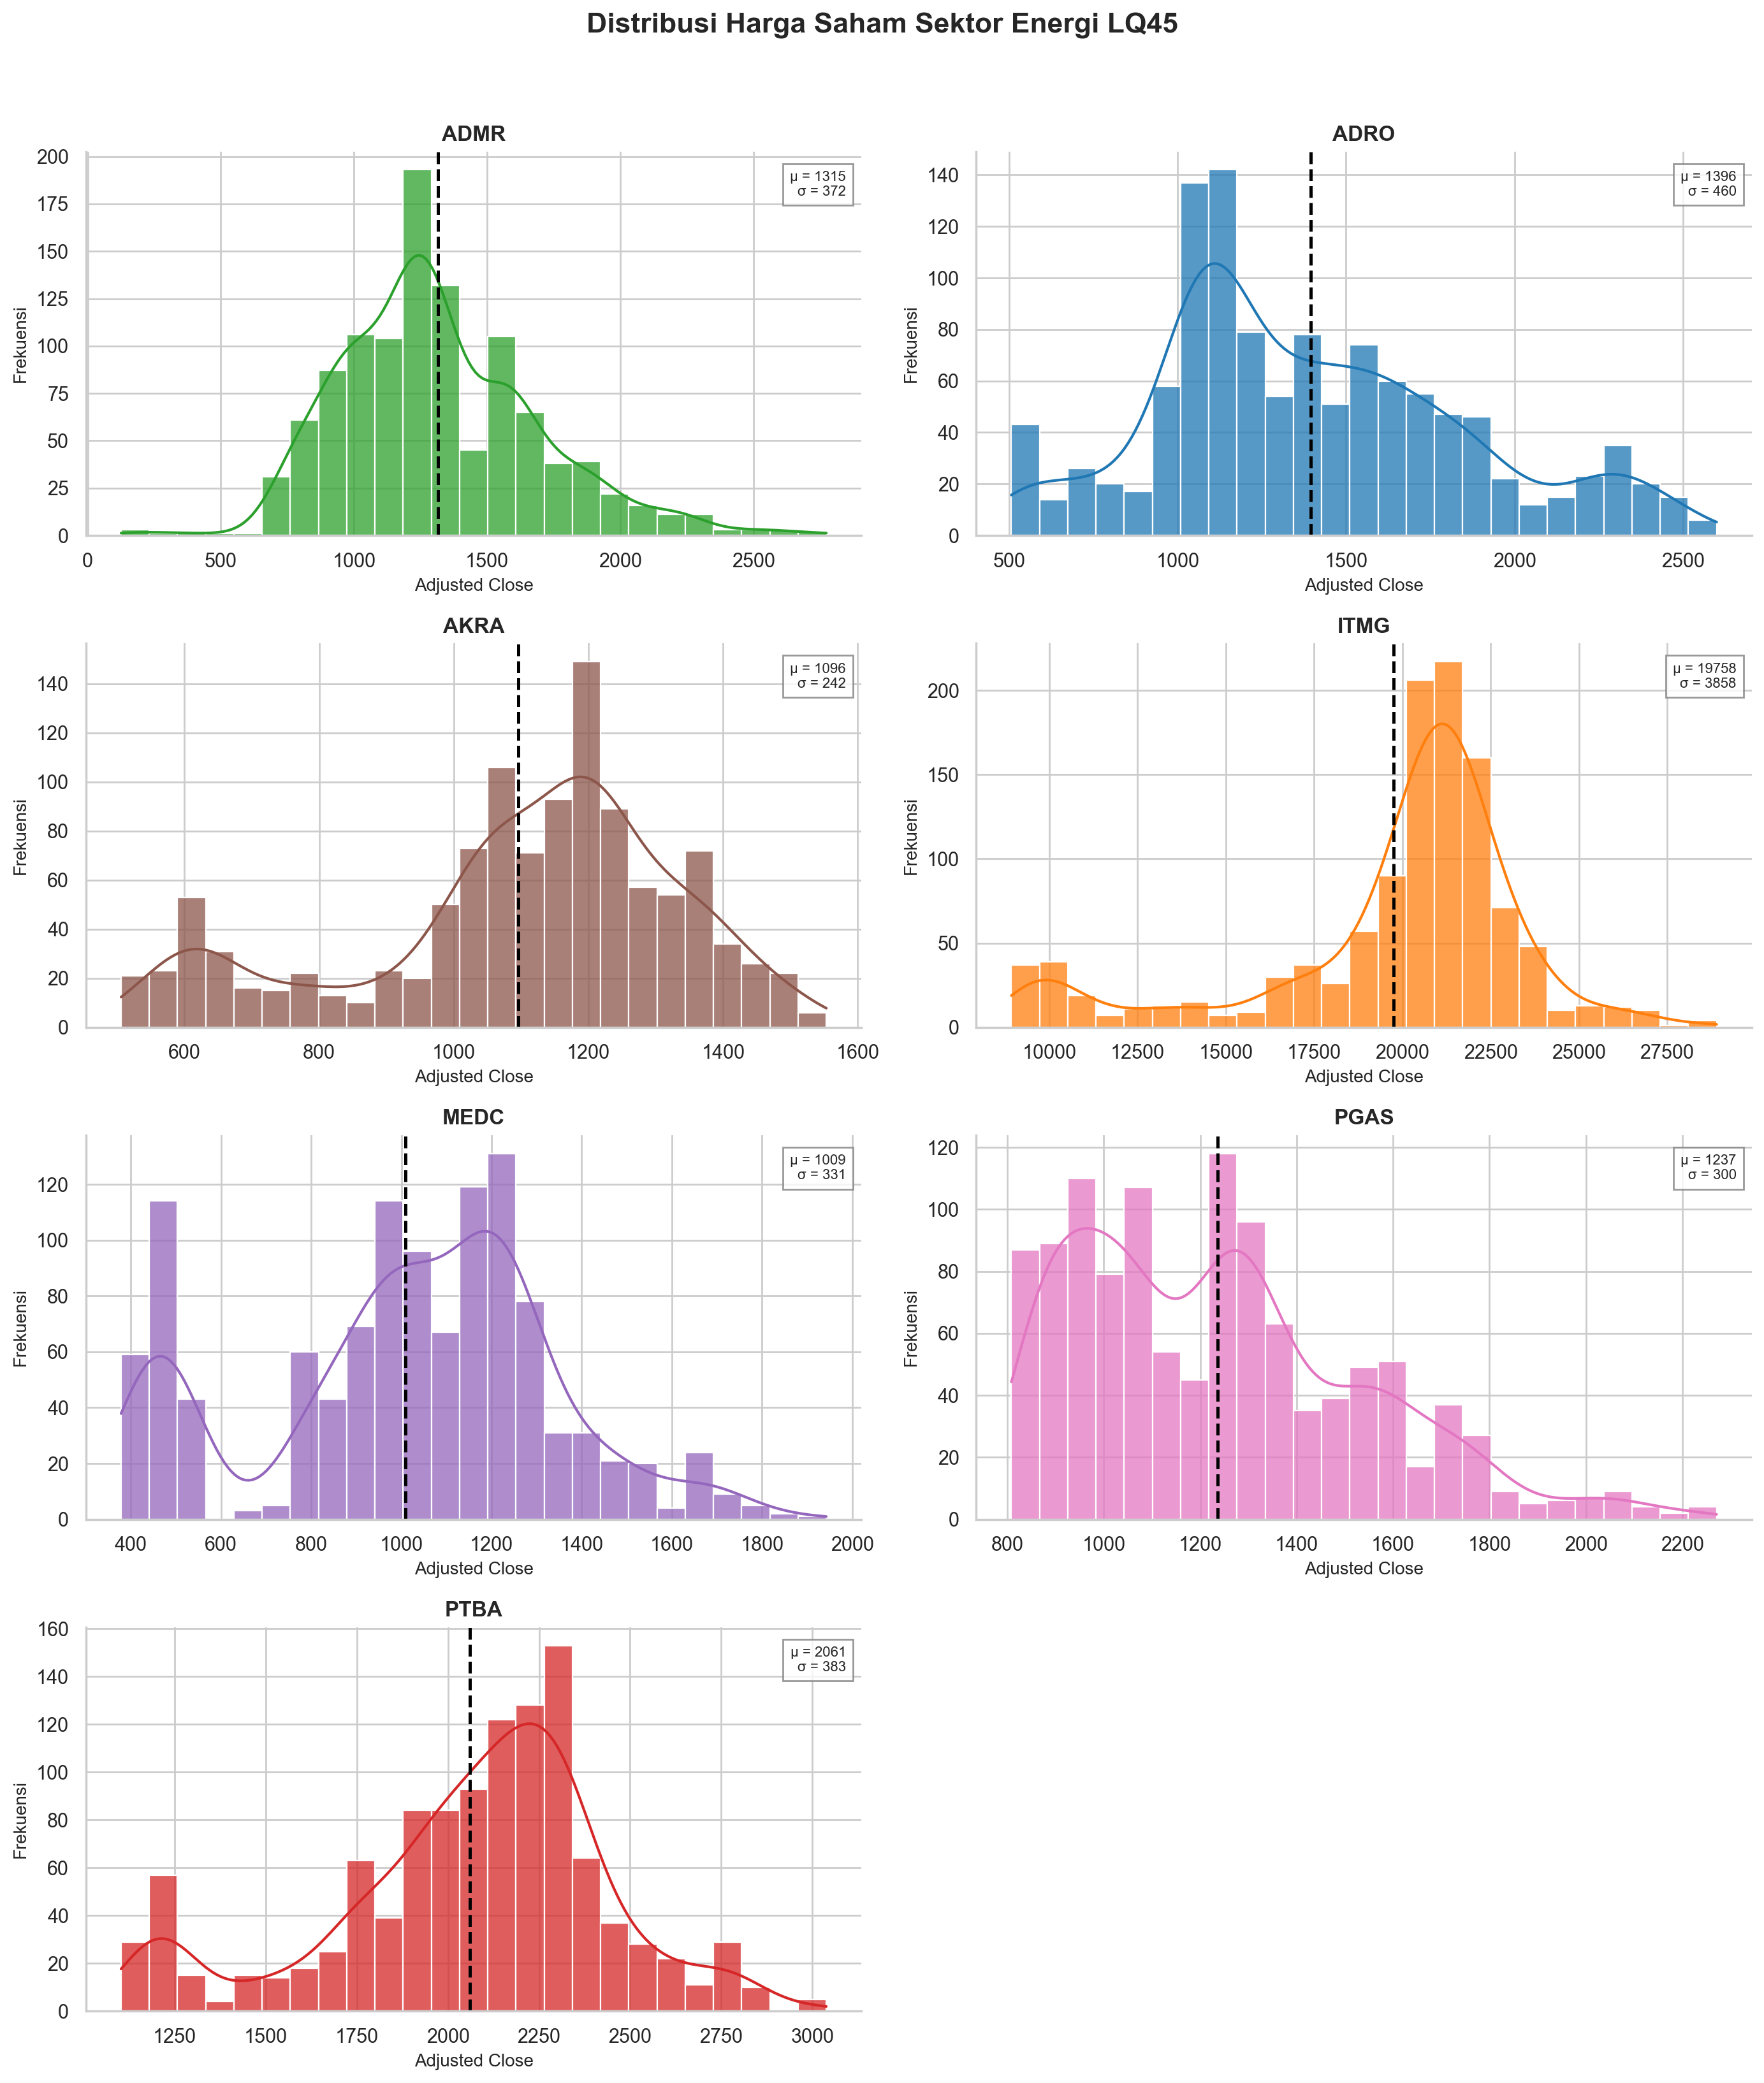

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Theme visual
sns.set_theme(style="whitegrid")

colors = {
    'ADRO': '#1f77b4',
    'ADMR': '#2ca02c',
    'ITMG': '#ff7f0e',
    'PTBA': '#d62728',
    'MEDC': '#9467bd',
    'AKRA': '#8c564b',
    'PGAS': '#e377c2'
}

emitens = sorted(df['Kode_Emiten'].unique())

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, kode in enumerate(emitens):
    ax = axes[i]
    subset = df[df['Kode_Emiten'] == kode][price_col].dropna()

    mean_val = subset.mean()
    std_val = subset.std()

    # Histogram + KDE
    sns.histplot(
        subset,
        bins=25,
        kde=True,
        color=colors[kode],
        alpha=0.75,
        edgecolor='white',
        linewidth=0.8,
        ax=ax
    )

    # Garis mean
    ax.axvline(
        mean_val,
        linestyle='--',
        linewidth=1.8,
        color='black',
        label=f'Mean = {mean_val:.0f}'
    )

    ax.set_title(
        f"{kode}",
        fontsize=12,
        fontweight='bold'
    )

    ax.set_xlabel("Adjusted Close", fontsize=10)
    ax.set_ylabel("Frekuensi", fontsize=10)

    # Statistik kecil di pojok
    ax.text(
        0.98, 0.95,
        f"μ = {mean_val:.0f}\nσ = {std_val:.0f}",
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=8,
        bbox=dict(
            facecolor='white',
            alpha=0.8,
            edgecolor='gray'
        )
    )

    # rapikan border
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Hapus subplot kosong
for j in range(len(emitens), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Distribusi Harga Saham Sektor Energi LQ45",
    fontsize=16,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Gambar_4_4_histogram_harga_saham_bagus.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## Simpan Output
Semua tabel dan gambar telah disimpan ke folder:
`06_dokumen_tesis/`

In [7]:
# ============================================================
# CELL 7 — SUMMARY OUTPUT
# ============================================================

files = [
    "missing_value_harga_saham.csv",
    "Tabel_4_5_statistik_deskriptif_harga.csv",
    "Tabel_ADF_Harga_Saham.csv",
    "Gambar_4_4_histogram_harga_saham.png"
]

print("Output berhasil disimpan:")
for file in files:
    print("-", OUTPUT_DIR / file)

Output berhasil disimpan:
- ..\..\06_dokumen_tesis\missing_value_harga_saham.csv
- ..\..\06_dokumen_tesis\Tabel_4_5_statistik_deskriptif_harga.csv
- ..\..\06_dokumen_tesis\Tabel_ADF_Harga_Saham.csv
- ..\..\06_dokumen_tesis\Gambar_4_4_histogram_harga_saham.png
